In [2]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import numpy as np 
import matplotlib.colors as colors

In [3]:
inputs_dir = "../1_inputs"
outputs_dir = "../3_outputs"
metadata_outputs = "../../1_allele_collection/3_outputs"

In [5]:
abun = pl.read_csv(f"{inputs_dir}/abun_scores.csv").select(["orf_id", "mut_id", "zscore_log2"]).unique().rename({
    "zscore_log2": "abun_score"
})
misloc = pl.read_csv(f"{inputs_dir}/misloc_scores.csv").select(["allele_0", "mean_auroc"]).unique().rename({
    "mean_auroc": "misloc_score"
})
ppi = pl.read_csv(f"{inputs_dir}/ppi_scores.csv").select(["orf_id", "mut_id", "normalized_distance"]).unique().rename({
    "normalized_distance": "ppi_score"
})
ai_scores = pl.read_csv(f"{inputs_dir}/ai_pred_struc_scores.tsv", separator="\t", infer_schema_length=10000)

In [6]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs}/varchamp_consolidated_alleles_clinvar_gnomad.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
metadata = metadata.unpivot(index=id_vars, 
                            on=mut_cols,
                            variable_name="mutation_collection",
                            value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id"),
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("allele_0")
)

In [18]:
# merge all scores
scores = metadata.join(abun, on=["orf_id", "mut_id"], how="left")
scores = scores.join(misloc, on="allele_0", how="left")
scores = scores.join(ppi, on=["orf_id", "mut_id"], how="left")
scores = scores.join(ai_scores.with_columns(
                        pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("allele_0"),
                        pl.col("AlphaMissense_rankscore").replace(".", None).cast(pl.Float64).alias("Alphamissense_score")
                    ), on=["allele_0"], how="left")

# Get rid of duplicates
scores = scores.drop(["orf_id", "mut_id"])
scores = scores.unique()

# Keep only alleles with at least one score
scores = scores.filter(
    ~(pl.col("abun_score").is_null() & pl.col("ppi_score").is_null() & pl.col("misloc_score").is_null())
)

scores.select(["symbol", "aa_change"]).unique().shape

(1309, 2)

In [30]:
scores

symbol,aa_change,ensembl_gene_id,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,abun_score,misloc_score,ppi_score,orf_id_right,symbol_right,nt_change,aa_change_right,ensembl_gene_id_right,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),…,Cytogenetic_dbnsfp_ai,ReviewStatus_dbnsfp_ai,NumberSubmitters_dbnsfp_ai,Guidelines_dbnsfp_ai,TestedInGTR_dbnsfp_ai,OtherIDs_dbnsfp_ai,SubmitterCategories_dbnsfp_ai,VariationID_dbnsfp_ai,PositionVCF_dbnsfp_ai,ReferenceAlleleVCF_dbnsfp_ai,AlternateAlleleVCF_dbnsfp_ai,SomaticClinicalImpact_dbnsfp_ai,SomaticClinicalImpactLastEvaluated_dbnsfp_ai,ReviewStatusClinicalImpact_dbnsfp_ai,Oncogenicity_dbnsfp_ai,OncogenicityLastEvaluated_dbnsfp_ai,ReviewStatusOncogenicity_dbnsfp_ai,SCVsForAggregateGermlineClassification_dbnsfp_ai,SCVsForAggregateSomaticClinicalImpact_dbnsfp_ai,SCVsForAggregateOncogenicityClassification_dbnsfp_ai,clinvar_nt_change_dbnsfp_ai,clinvar_aa_change_dbnsfp_ai,RefSeq_mRNA_dbnsfp_ai,StarStatus_dbnsfp_ai,clinvar_clnsig_clean_dbnsfp_ai,plddt,rsa,plddt_f32,rsa_f32,rsa_cat,plddt_cat,AM_pred,Provean_pred,AlphaMissense_ClinVar,Provean_ClinVar,ESM1b_ClinVar,Alphamissense_score
str,str,str,str,f64,f64,str,f64,f64,f64,i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,…,str,str,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,f64,f64,f64,f64,str,str,str,str,str,str,str,f64
"""DES""","""Ala213Val""","""ENSG00000175084""","""3_Conflicting""",0.0145752,1.0,"""DES_Ala213Val""",null,0.635391,null,12573,"""DES""","""638C>T""","""Ala213Val""","""ENSG00000175084""","""2""",219420154,"""NC_000002.12:219420154:C:T""","""ALE00007811""","""CCSBVarC007825""","""NULL""","""NULL""","""2264""","""GDEhDisVCh_40003""","""A06""","""Edgotyping3""","""ATGAGCCAGGCCTACTCGTCCAGCCAGCGC…",53432.0,"""single nucleotide variant""","""NM_001927.4(DES):c.638C>T (p.A…",1674.0,"""DES""","""HGNC:2770""","""Conflicting classifications of…",1.0,"""Feb 02, 2025""",4.1272699e7,…,"""2q35""","""criteria provided, conflicting…",22,"""ACMG2022""","""N""","""ClinGen:CA133860,UniProtKB:P17…",2,44265,219420154,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000051520|SCV000060902|SCV0…","""-""","""-""","""638C>T ""","""Ala213Val""","""NM_001927.4""",1,"""3_Conflicting""",96.16,0.518868,96.16,0.5188679,"""10-90""",""">90""","""2_Benign""","""2_Neutral""","""2_Benign""","""2_Benign""","""2_Benign""",0.48973
"""KRT6A""","""Val523Phe""","""ENSG00000205420""","""2_Benign""",null,2.0,"""KRT6A_Val523Phe""",-0.075262,0.565814,null,4870,"""KRT6A""","""1567G>T""","""Val523Phe""","""ENSG00000205420""","""12""",52487848,"""NC_000012.12:52487848:C:A""","""ALE00002920""","""CCSBVarC002920""","""900200""","""NULL""","""NULL""","""GDEhDisVCh_40048""","""B11""","""RC4""","""ATGGCCAGCACATCCACCACCATCAGGAGC…",1.610223e6,"""single nucleotide variant""","""NM_005554.4(KRT6A):c.1567G>T (…",3853.0,"""KRT6A""","""HGNC:6443""","""Benign""",0.0,"""Jan 29, 2025""",6.2617088e7,…,"""12q13.13""","""criteria provided, multiple su…",2,"""-""","""N""","""ClinGen:CA6581759""",2,1601017,52487848,"""C""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV002410267|SCV005229529""","""-""","""-""","""1567G>T ""","""Val523Phe""","""NM_005554.4""",2,"""2_Benign""",30.21,1.0,30.21,1.0,"""$\geqslant$90""","""<=50""","""2_Benign""","""2_Neutral""","""2_Benign""","""2_Benign""","""2_Benign""",0.066
"""KCNJ2""","""Arg260Pro""","""ENSG00000123700""","""1_Pathogenic""",null,1.0,"""KCNJ2_Arg260Pro""",-5.805146,null,NaN,100016069,"""KCNJ2""","""779G>C""","""Arg260Pro""","""ENSG00000123700""","""17""",70175818,"""NC_000017.11:70175818:G:C""","""ALE00008324""","""CCSBVarC008338""","""NULL""","""NULL""","""2636""","""GDEhDisVCh_40005""","""A10"""

<Axes: xlabel='Alphamissense_score', ylabel='Count'>

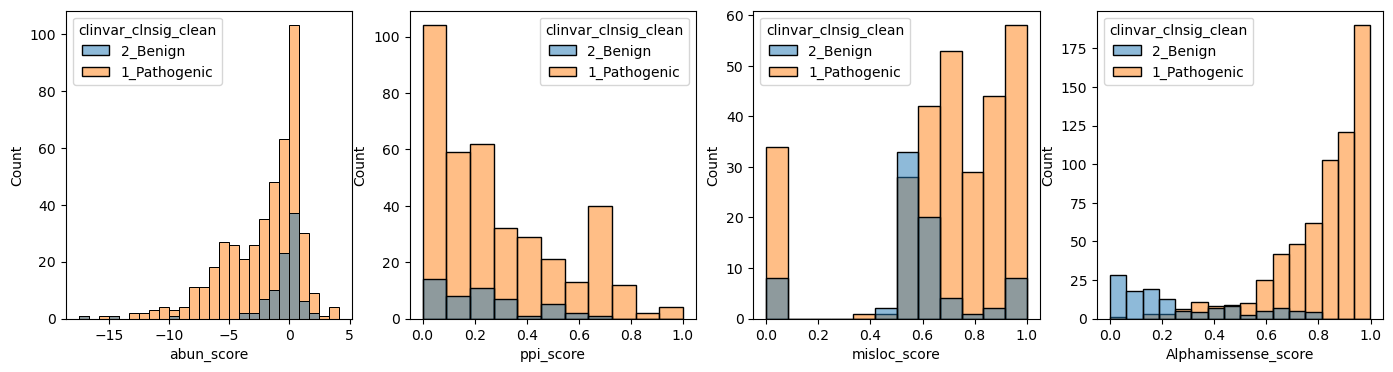

In [20]:
fig, axes = plt.subplots(1,4,figsize=(17,4))
sns.histplot(scores.filter(
                (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))
            ), x="abun_score", hue="clinvar_clnsig_clean", ax=axes[0])

sns.histplot(scores.filter(
                (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))
            ), x="ppi_score", hue="clinvar_clnsig_clean", ax=axes[1])

sns.histplot(scores.filter(
                (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))
            ), x="misloc_score", hue="clinvar_clnsig_clean", ax=axes[2])

sns.histplot(scores.filter(
                (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))
            ), x="Alphamissense_score", hue="clinvar_clnsig_clean", ax=axes[3])

In [28]:
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_auc_score, roc_curve
set2_palette = sns.color_palette("Set2")

def plot_auroc_curves(df_clinvar_w_scores, pos_label, methods, set2_palette=set2_palette):
    """
    For each method, plot the adjusted PR curve (with both balanced and monotonized adjustments)
    and compute the adjusted AUPRC via bootstrapping. Also perform pairwise significance testing 
    of the AUPRC across different RSA categories.
    
    Parameters
    ----------
    df_clinvar_w_scores : Polars DataFrame
        Input data including columns "clinvar_clnsig_clean", category and predictor scores.
    methods : list of str
        List of method names corresponding to score columns in the data.
    set2_palette : list of str
        List of colors (e.g., from a color palette) to use for different RSA categories.
    n_bootstrap : int, optional
        Number of bootstrap iterations for significance testing (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    ap_results : dict
        Dictionary of adjusted AUPRC values and bootstrap distributions, structured as:
          { method: { category: {"AP": <adjusted AUPRC>, "boot_ap": <bootstrap array> } } }
    significance : dict
        Dictionary mapping each method to a DataFrame of pairwise p-values comparing AUPRC between categories.
    """
    ap_results_dict = {}
    # sig_results_dict = {}
    fig, axes = plt.subplots(1, 1, figsize=(6, 5))
        
    ap_results = {}  # to store adjusted AUPRC and bootstrap distributions
    # significance = {}  # to store pairwise significance p-values per method
    
    for m_idx, met in enumerate(methods):
        ap_results[met] = {}
        # Filter data for current category and valid clinical labels.
        df_clin_per_method = df_clinvar_w_scores.filter(
            (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))
        ).with_columns(
            (
                pl.when(pl.col("clinvar_clnsig_clean") == pos_label)
                .then(1)
                .otherwise(0)
            ).alias("clinvar_label")
        ).drop_nulls(subset=["clinvar_clnsig_clean", met])
        
        # Convert to pandas DataFrame.
        df_pd = df_clin_per_method.to_pandas()
        df_pd = df_pd[["clinvar_label", met]].dropna()
        # Convert clinvar_label to boolean.
        truth = df_pd["clinvar_label"].astype(bool)
        # Create a scores DataFrame (with one column).
        scores = df_pd[[met]]
        # Create the YogiROC2 object using the new YogiROC2() constructor.
        fpr, tpr, thresholds = roc_curve(truth, scores)
        # Get the performance table from the YogiROC2 object.
        auc_score = roc_auc_score(truth, scores)
        ap_results[met] = auc_score

        # Plot the adjusted PR curve.
        axes.plot(100 * fpr, 100 * tpr,
                label=f"{met}: {auc_score:.2f}",
                color=set2_palette[methods.index(met)])
        # Plot chance level as a horizontal dashed line.
        # axes[m_idx].axhline(y=100 * prior, color=set2_palette[plddt_cats.index(cat)], ls="--")
    # Customize the subplot.
    handles, labels = axes.get_legend_handles_labels()
    # order = [2,1,0] if "rsa" in category else [3,1,0,2]
    precision_label = "True Positive Rate (%)"
    # title = f"AUROC by {category}"
    
    axes.legend(loc="lower left",
                    title="Assay")
    axes.set_xlabel("False Positive Rate (%)")
    axes.set_ylabel(precision_label)
    # axes[m_idx].set_title(met.split("_")[0])
    axes.grid()
    plt.tight_layout()
    plt.show()
    # plt.subplots_adjust(wspace=0.04)
    
    return ap_results_dict ## , sig_results_dict

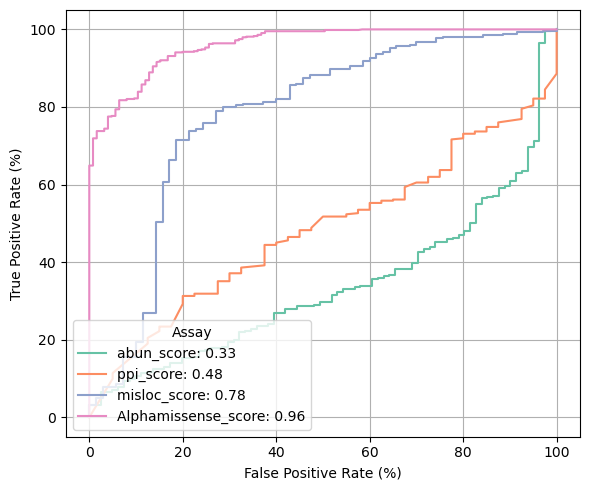

{}

In [ ]:
scores = scores.with_columns(pl.col("ppi_score").neg().alias("ppi_score"))

plot_auroc_curves(scores, "1_Pathogenic", methods=["abun_score", "ppi_score", "misloc_score", "Alphamissense_score"])

966
717
654
shape: (1_728, 522)
┌────────┬───────────┬────────────┬────────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ symbol ┆ aa_change ┆ ensembl_ge ┆ clinvar_cl ┆ … ┆ abun_scor ┆ ppi_score ┆ misloc_sc ┆ Max_ranks │
│ ---    ┆ ---       ┆ ne_id      ┆ nsig_clean ┆   ┆ e_ranksco ┆ _rankscor ┆ ore_ranks ┆ core      │
│ str    ┆ str       ┆ ---        ┆ ---        ┆   ┆ re        ┆ e         ┆ core      ┆ ---       │
│        ┆           ┆ str        ┆ str        ┆   ┆ ---       ┆ ---       ┆ ---       ┆ f64       │
│        ┆           ┆            ┆            ┆   ┆ f64       ┆ f64       ┆ f64       ┆           │
╞════════╪═══════════╪════════════╪════════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ DES    ┆ Ala213Val ┆ ENSG000001 ┆ 3_Conflict ┆ … ┆ null      ┆ null      ┆ 0.350153  ┆ 0.635391  │
│        ┆           ┆ 75084      ┆ ing        ┆   ┆           ┆           ┆           ┆           │
│ KRT6A  ┆ Val523Phe ┆ ENSG000002 ┆ 2_Benign   ┆ … ┆ 0.6542

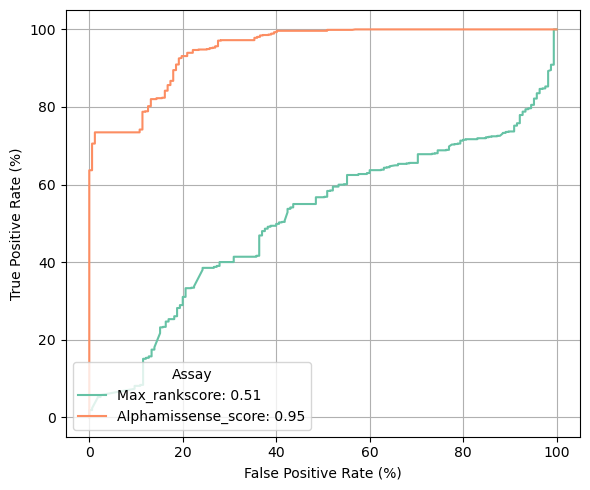

{}

In [ ]:
# List of score columns to rank
score_cols = ["abun_score", "ppi_score", "misloc_score"]

# Start with base DataFrame
result = scores

# Loop through each column and compute rankscore
for col in score_cols:
    # Drop nulls only from this column
    non_null_df = scores.select(["allele_0", col]).drop_nulls(subset=[col])
    n = non_null_df.height  # total non-null values
    print(n)

    # Rank + normalize
    ranked = non_null_df.with_columns(
        (pl.col(col).rank("average") / n)
        .alias(f"{col}_rankscore")
    )

    # Join back to main DataFrame on variant_id
    result = result.join(ranked.select(["allele_0", f"{col}_rankscore"]), on="allele_0", how="left")

# Add a new column that takes the maximum of the two rankscore columns
result = result.with_columns([
    pl.max_horizontal([
        pl.col("abun_score_rankscore"),
        pl.col("ppi_score_rankscore"),
        pl.col("misloc_score")
    ]).alias("Max_rankscore")
])

print(result)
plot_auroc_curves(result, "1_Pathogenic", methods=["Max_rankscore","Alphamissense_score"])

In [39]:
# sns.regplot(result, x="Max_rankscore", y="misloc_score")